In [1]:
from transformers import AutoTokenizer
import torch
import os
import pandas as pd
import numpy as np
import pickle
import glob
import re
import matplotlib.pyplot as plt
from scipy import stats
from tqdm.notebook import tqdm
import seaborn as sns
from sklearn.metrics.pairwise import cosine_distances
import string
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats import multitest
from statsmodels.stats.anova import AnovaRM 
import itertools
import sys
sys.path.append('..')
from utils import get_segmentation_indices,segmentation_to_word_list
from utils import calculate_cross_entropy,normalize_entropy,model_to_path_dict

In [2]:
def get_significance(p_val):
    if p_val < 0.001:
        return "***"
    elif p_val < 0.01:
        return "**"
    elif p_val < 0.05:
        return "*"
    else:
        return "ns"
    
def add_brackets(ax, pair, significance, bars, offset):
    # Get the index of the bars from the pair
    bar1_index = list(means.index).index(pair[0])
    bar2_index = list(means.index).index(pair[1])
    
    # Get the y-values of the bars for each pair
    y1 = bars[bar1_index].get_height() + bars[bar1_index].get_y()
    y2 = bars[bar2_index].get_height() + bars[bar2_index].get_y()

    # Determine the max y for placing the bracket and label
    y_max = max(y1, y2) + offset  # Add space between brackets
    
    # Add the line (bracket) between the two bars
    ax.plot([bar1_index, bar2_index], [y_max, y_max], color='black', lw=2)
    
    # Add significance stars or "ns" above the bracket
    ax.text((bar1_index + bar2_index) / 2, y_max, significance, ha='center', va='bottom', fontsize=7)


In [3]:
uniform_preds = ['weighted_event_info_by_duration','weighted_event_info','weighted_event_info_conditioned','weighted_event_info_kl','weighted_event_info_sylber_ce','weighted_event_info_exponential_saturation']
controls = ['H_event_conditioned','H_event','event_kl','event_len','event_duration','sylber_ce']
uniform_preds_punctuated = uniform_preds +['weighted_event_info_conditioned_punctuated','weighted_event_info_kl_punctuated']
controls_punctuated = controls +['event_kl_punctuated','event_surprisal_punctuated']


In [4]:
np.unique(controls+uniform_preds_punctuated+controls_punctuated)

array(['H_event', 'H_event_conditioned', 'event_duration', 'event_kl',
       'event_kl_punctuated', 'event_len', 'event_surprisal_punctuated',
       'sylber_ce', 'weighted_event_info',
       'weighted_event_info_by_duration',
       'weighted_event_info_conditioned',
       'weighted_event_info_conditioned_punctuated',
       'weighted_event_info_exponential_saturation',
       'weighted_event_info_kl', 'weighted_event_info_kl_punctuated',
       'weighted_event_info_sylber_ce'], dtype='<U42')

In [5]:
plotting_label_dict = {
    "weighted_event_info": "CRUISE (Number of tokens)",
    "weighted_event_info_by_duration": "CRUISE (Duration)", 
    "weighted_event_info_exponential_saturation":"CRUISE (Duration with saturation)",
    "weighted_event_info_conditioned": "Surprisal-weighted sampling",
    "weighted_event_info_kl":"KL-weighted sampling", 
    "weighted_event_info_sylber_ce": "Acoustic surprisal-weighted sampling",
    'H_event_conditioned': "Surprisal",
    'H_event': "Total information",
    'event_duration': "Duration",
    "event_len": "Number of tokens",
    "chunk_type":"Event boundary",
    "event_kl":"Relative entropy",
    "chunk_type":"Event boundary",
    "chunk_type_sr":"Event boundary",
    "sylber_ce":"Acoustic surprisal",
}
plotting_label_dict_sm = {
    "weighted_event_info_by_duration": "CRUISE", 
    "weighted_event_info_conditioned": "Surprisal-weighted sampling",
    'H_event_conditioned': "Surprisal",
    'H_event': "Total information",
    'event_duration': "Duration",
    "event_len": "Number of tokens",
    "event_kl":"Relative entropy",
    "weighted_event_info_exponential_saturation":"CRUISE (Saturation)",
}
plotting_label_dict_punctuated = plotting_label_dict.copy()
plotting_label_dict_punctuated["event_kl_punctuated"] = "Relative entropy punctuated"
plotting_label_dict_punctuated["event_surprisal_punctuated"] = "surprisal punctuated"
plotting_label_dict_punctuated["weighted_event_info_conditioned_punctuated"] = "Surprisal-weighted sampling punctuated"
plotting_label_dict_punctuated["weighted_event_info_kl_punctuated"] = "KL-weighted sampling punctuated"

plot_fontsize = 8

## load uniform encoding dfs and saturation pred

In [6]:
def get_uniform_encoding_df(parent_save_dir,uniform_encoding_df_name,model_save_dir_name,split_df = None,sr = False):
    uniform_encoding_dfs = []
    for story in stories:
        uniform_encoding_save_dir = os.path.join(parent_save_dir,model_save_dir_name,'uniform_encoding',story)
        story_uniform_encoding_df = pd.read_csv(os.path.join(uniform_encoding_save_dir,uniform_encoding_df_name))
        story_uniform_encoding_df['story'] = story
        uniform_encoding_dfs.append(story_uniform_encoding_df)
    all_uniform_encoding_dfs = pd.concat(uniform_encoding_dfs,ignore_index = True)
    all_uniform_encoding_dfs = all_uniform_encoding_dfs.rename(columns={'H(event|prev events)': "H_event_conditioned", "H(event)": "H_event"})
    all_uniform_encoding_dfs['story_idx'] = ['Story '+str(story_to_idx_mapping[s]) for s in all_uniform_encoding_dfs['story'].values]
    
    if split_df is not None:
        all_uniform_encoding_dfs['chunk_type'] = ['Boundary' if i else 'Inner' for i in split_df['has_boundary']]
    if sr:
        all_uniform_encoding_dfs['chunk_type_sr'] = ['Boundary' if i else 'Inner' for i in split_df['has_boundary_sr']]
    return all_uniform_encoding_dfs

In [7]:
adjusted = True
punctuated = False
save_dir = '../../generated'
sr_save_dir = '../../exp2/generated'
model_name = 'Llama3-8b-instruct' #'Llama3-8b'
model_save_dir_name = model_to_path_dict[model_name]['save_dir_name']
model_initial_char = model_to_path_dict[model_name]['initial_char']
figure_save_dir = os.path.join(save_dir,model_save_dir_name,'uniform_encoding','figures_even_split','adjusted')
if adjusted:
    uniform_encoding_df_basename_timing = 'uniform_encoding_df_even_split_adjusted'
    mutual_info_save_dir_name = 'story_split_timing_adjusted'
    figure_save_dir = os.path.join(save_dir,model_save_dir_name,'uniform_encoding','figures_even_split','adjusted')
else:
    uniform_encoding_df_basename_timing = 'uniform_encoding_df_even_split'
    mutual_info_save_dir_name = 'story_split_timing'
    figure_save_dir = os.path.join(save_dir,model_save_dir_name,'uniform_encoding','figures_even_split')
if not os.path.exists(figure_save_dir):
    os.makedirs(figure_save_dir)

stories = ['pieman','alternateithicatom','odetostepfather','souls','legacy','wheretheressmoke','adventuresinsayingyes','inamoment']
story_to_idx_mapping = {s:stories.index(s)+1 for s in stories}

uniform_encoding_df_sr_original_name_timing = uniform_encoding_df_basename_timing+'_sr_original.csv'
uniform_encoding_df_sr_shrink_name_timing = uniform_encoding_df_basename_timing+'_sr_shrink.csv'
uniform_encoding_df_exp1_name_timing = uniform_encoding_df_basename_timing+'.csv'
all_uniform_encoding_dfs_original_split_by_timing = get_uniform_encoding_df(sr_save_dir,uniform_encoding_df_sr_original_name_timing,model_save_dir_name)
all_uniform_encoding_dfs_shrink_split_by_timing = get_uniform_encoding_df(sr_save_dir,uniform_encoding_df_sr_shrink_name_timing,model_save_dir_name)
all_uniform_encoding_dfs_exp1_split_by_timing = get_uniform_encoding_df(save_dir,uniform_encoding_df_exp1_name_timing,model_save_dir_name)
all_uniform_encoding_dfs = {'original_exp':all_uniform_encoding_dfs_exp1_split_by_timing,'original_sr':all_uniform_encoding_dfs_original_split_by_timing,'shrink_sr':all_uniform_encoding_dfs_shrink_split_by_timing}

exclusion_dir = os.path.join('../../behavior_data','exclusion')
stories = ['pieman','alternateithicatom','odetostepfather','souls','legacy','wheretheressmoke','adventuresinsayingyes','inamoment']
story_to_idx_mapping = {s:stories.index(s)+1 for s in stories}

uniform_preds_colors = {p:sns.color_palette("light:#005F5F_r", len(uniform_preds)+1)[i] for i,p in enumerate(uniform_preds)}
controls_colors= {p:sns.color_palette("light:#FFBF00", len(controls)+1)[i+1] for i,p in enumerate(controls)}
all_colors = {**uniform_preds_colors, **controls_colors}

instruct = False
recall_first = True


In [8]:
if recall_first and not instruct:
    plot_target = 'mean_ER_intersect'
    recall_str = 'recall first'
    inst_str = 'direct concatenation'
elif recall_first and instruct:
    plot_target = 'mean_ER_intersect_instruct'
    recall_str = 'recall first'
    inst_str = 'instruction prompted'
elif not recall_first and not instruct:
    plot_target = 'mean_ER_intersect_recall_last'
    recall_str = 'recall last'
    inst_str = 'direct concatenation'
elif not recall_first and instruct:
    plot_target = 'mean_ER_intersect_instruct_recall_last'
    recall_str = 'recall last'
    inst_str = 'instruction prompted'

In [11]:
def get_capacity_preds(parent_save_dir,capacity_model_dict_name,model_save_dir_name):
    all_stories_capacity_model_dict = None
    for story in stories:
        uniform_encoding_save_dir = os.path.join(parent_save_dir,model_save_dir_name,'uniform_encoding',story)
        with open(os.path.join(uniform_encoding_save_dir,capacity_model_dict_name),'rb') as f:
            capacity_model_dict = pickle.load(f)
        exponential_uniform_encoding_dict = capacity_model_dict['exponential_uniform_encoding']
        if not all_stories_capacity_model_dict: # check if empty
            all_stories_capacity_model_dict = {c:[] for c in list(exponential_uniform_encoding_dict.keys())}
        for c in exponential_uniform_encoding_dict.keys():
            all_stories_capacity_model_dict[c].extend(exponential_uniform_encoding_dict[c])
    for c in all_stories_capacity_model_dict.keys():
        all_stories_capacity_model_dict[c] = np.array(all_stories_capacity_model_dict[c])
        
    return all_stories_capacity_model_dict,list(exponential_uniform_encoding_dict.keys())

In [9]:
# duration saturation model 
tau_thresh = 2
def get_saturation_duration_pred(uniform_encoding_df_exp1_name,uniform_encoding_df_sr_original_name,uniform_encoding_df_sr_shrink_name,calibration_temp = None):
    all_models_saturation_duration_pred_dict = {}
    model_save_dir_name = model_to_path_dict[model_name]['save_dir_name']
    caltemp_suffix = '_caltemp_%.2f'%calibration_temp if calibration_temp is not None else ''
    capacity_model_dict_exp1_name = uniform_encoding_df_exp1_name.replace('uniform_encoding_df', 'duration_exponential_saturation')
    capacity_model_dict_exp1_name = capacity_model_dict_exp1_name.replace('.csv','.pkl')
    
    capacity_model_dict_sr_original_name = uniform_encoding_df_sr_original_name.replace('uniform_encoding_df', 'duration_exponential_saturation')
    capacity_model_dict_sr_original_name = capacity_model_dict_sr_original_name.replace('.csv','.pkl')
    
    capacity_model_dict_sr_shrink_name = uniform_encoding_df_sr_shrink_name.replace('uniform_encoding_df', 'duration_exponential_saturation')
    capacity_model_dict_sr_shrink_name = capacity_model_dict_sr_shrink_name.replace('.csv','.pkl')
    
    capacity_model_dict_exp1,taus = get_capacity_preds(save_dir,capacity_model_dict_exp1_name,model_save_dir_name)
    capacity_model_dict_sr_original,_ = get_capacity_preds(sr_save_dir,capacity_model_dict_sr_original_name,model_save_dir_name)
    capacity_model_dict_sr_shrink,_ = get_capacity_preds(sr_save_dir,capacity_model_dict_sr_shrink_name,model_save_dir_name)

    # only keep tau > tau_thresh?
    capacity_model_dict_exp1 = {k: v for k, v in capacity_model_dict_exp1.items() if k > tau_thresh}
    capacity_model_dict_sr_original = {k: v for k, v in capacity_model_dict_sr_original.items() if k > tau_thresh}
    capacity_model_dict_sr_shrink = {k: v for k, v in capacity_model_dict_sr_shrink.items() if k > tau_thresh}
    taus = [t for t in taus if t > tau_thresh]
    saturation_duration_pred_dict = {'original_exp':capacity_model_dict_exp1,
                                                'original_sr':capacity_model_dict_sr_original,
                                                'shrink_sr':capacity_model_dict_sr_shrink}
    return saturation_duration_pred_dict,taus

In [12]:
saturation_duration_pred_dict,taus =get_saturation_duration_pred(uniform_encoding_df_exp1_name_timing,uniform_encoding_df_sr_original_name_timing,uniform_encoding_df_sr_shrink_name_timing)

In [13]:
# load saturation model
metrics_save_dir = os.path.join(save_dir,'metrics')
all_models_best_tau = pd.read_csv(os.path.join(metrics_save_dir,'all_models_best_tau.csv'))

pred = 'weighted_event_info_exponential_saturation'
memory_targets = ['mean_ER_intersect','mean_ER_intersect_recall_last', 'mean_ER_intersect_instruct','mean_ER_intersect_instruct_recall_last']
pred_dict = saturation_duration_pred_dict['original_exp']
pred_dict_shrink = saturation_duration_pred_dict['shrink_sr']

split_by_token_best_tau = all_models_best_tau[(all_models_best_tau['model']==model_name) & (all_models_best_tau['target']==plot_target)]['best_tau'].values[0]
all_uniform_encoding_dfs['original_exp'][pred] = pred_dict[split_by_token_best_tau]
all_uniform_encoding_dfs['original_sr'][pred] = pred_dict[split_by_token_best_tau]
all_uniform_encoding_dfs['shrink_sr'][pred] = pred_dict_shrink[split_by_token_best_tau]    

## original experiment

In [14]:

# with open(os.path.join(save_dir,model_save_dir_name,'uniform_encoding','even_split_by_timing_adjusted_variable_g_ir.pkl'),'rb') as f:
#     best_timing_pred = pickle.load(f)

all_stories_corr_df = []
for story in stories:
    exclusion_df = pd.read_csv(os.path.join(exclusion_dir,'%s_exclusion.csv'%story))
    excluded_subjects = exclusion_df['excluded'].loc[exclusion_df['recall']==1].values 

    pairwise_event_save_dir = os.path.join(save_dir,model_save_dir_name,'pairwise_event',story,mutual_info_save_dir_name)
    recall_explained_event_info_df_raw = pd.read_csv(os.path.join(pairwise_event_save_dir,'recall_explained_event_ce_df.csv'))
    recall_explained_event_info_df_raw = recall_explained_event_info_df_raw[~recall_explained_event_info_df_raw['subject'].isin(excluded_subjects)]

    event_explained_recall_info_df_raw = pd.read_csv(os.path.join(pairwise_event_save_dir,'event_explained_recall_ce_df.csv'))
    event_explained_recall_info_df_raw = event_explained_recall_info_df_raw[~event_explained_recall_info_df_raw['subject'].isin(excluded_subjects)]

    recall_explained_event_info_df_instruct = pd.read_csv(os.path.join(pairwise_event_save_dir,'instruct','recall_explained_event_ce_df.csv'))
    recall_explained_event_info_df_instruct = recall_explained_event_info_df_instruct[~recall_explained_event_info_df_instruct['subject'].isin(excluded_subjects)]

    event_explained_recall_info_df_instruct = pd.read_csv(os.path.join(pairwise_event_save_dir,'instruct','event_explained_recall_ce_df.csv'))
    event_explained_recall_info_df_instruct = event_explained_recall_info_df_instruct[~event_explained_recall_info_df_instruct['subject'].isin(excluded_subjects)]

    uniform_encoding_save_dir = os.path.join(save_dir,model_save_dir_name,'uniform_encoding',story)
    #story_uniform_encoding_df = pd.read_csv(os.path.join(uniform_encoding_save_dir,uniform_encoding_df_name))
    story_uniform_encoding_df = all_uniform_encoding_dfs['original_exp'].loc[all_uniform_encoding_dfs['original_exp']['story']==story].copy()
    story_uniform_encoding_df = story_uniform_encoding_df.reset_index()
    story_uniform_encoding_df = story_uniform_encoding_df.rename(columns={'H(event|prev events)': "H_event_conditioned", "H(event)": "H_event"})
    
    subjects = []
    static_preds = np.unique(controls+uniform_preds)
    #static_preds = np.unique(controls+uniform_preds_punctuated+controls_punctuated)
    static_preds_corr = {pred:[] for pred in static_preds}
    #variable_g_preds_corr = {pred:[] for pred in best_timing_pred.keys()}
    if instruct:
        if recall_first:
            target_df = recall_explained_event_info_df_instruct
        else:
            target_df = event_explained_recall_info_df_instruct
    else:
        if recall_first:
            target_df = recall_explained_event_info_df_raw
        else:
            target_df = event_explained_recall_info_df_raw
    
    for subject,subject_df in target_df.groupby('subject'):
        ER_intersect = subject_df['ER_intersect'].values
        subjects.append(subject)
        for pred in static_preds:
            pred_story_val = story_uniform_encoding_df[pred]
            static_preds_corr[pred].append(np.corrcoef(ER_intersect,pred_story_val)[0,1])
            
        
#         for pred in best_timing_pred.keys():
#             pred_story_val = best_timing_pred[pred][story]
#             variable_g_preds_corr[pred].append(np.corrcoef(ER_intersect,pred_story_val)[0,1])
    recall_first_corr_df = pd.DataFrame({'subject':subjects,
                                        'story':story})
    for pred in static_preds:
        recall_first_corr_df[pred] = static_preds_corr[pred]
#     for pred in best_timing_pred.keys():
#         recall_first_corr_df[pred] = variable_g_preds_corr[pred]
    all_stories_corr_df.append(recall_first_corr_df)
all_stories_corr_df = pd.concat(all_stories_corr_df, ignore_index =True)


In [15]:
all_stories_corr_df.columns

Index(['subject', 'story', 'H_event', 'H_event_conditioned', 'event_duration',
       'event_kl', 'event_len', 'sylber_ce', 'weighted_event_info',
       'weighted_event_info_by_duration', 'weighted_event_info_conditioned',
       'weighted_event_info_exponential_saturation', 'weighted_event_info_kl',
       'weighted_event_info_sylber_ce'],
      dtype='object')

In [16]:
def prob_to_z(prob,n):
    return (prob-0.5)/np.sqrt(0.5**2/n)

In [17]:
def get_all_story_z(big_corr_df,uniform_preds,targets):
    all_story_p = {}
    all_story_prop ={}
    all_story_corrected_p = {}
    all_story_z = {}
    all_story_z_reversed = {}
    for story in stories:
        this_story_df = big_corr_df.loc[big_corr_df['story']==story]
        this_story_p_matrix = pd.DataFrame(np.nan, index=uniform_preds, columns=targets)
        this_story_prop_matrix = pd.DataFrame(np.nan, index=uniform_preds, columns=targets)
        this_story_z_matrix = pd.DataFrame(np.nan, index=uniform_preds, columns=targets)
        this_story_z_reversed_matrix = pd.DataFrame(np.nan, index=uniform_preds, columns=targets)
        n = len(this_story_df)
        for pred in uniform_preds:
            for control_pred in targets:
                if pred==control_pred:
                    continue
                successes = np.sum(this_story_df[pred]>this_story_df[control_pred])
                success_prob = successes/n
                success_z = prob_to_z(success_prob,n)

                failures = np.sum(this_story_df[control_pred]>this_story_df[pred])
                failures_prob = failures/n
                failures_z = prob_to_z(failures_prob,n)

                p = stats.binomtest(successes, n=n, p=0.5, alternative='greater')
                this_story_p_matrix.loc[pred,control_pred] = p.pvalue
                this_story_prop_matrix.loc[pred,control_pred] =p.statistic
                this_story_z_matrix.loc[pred,control_pred] = success_z
                this_story_z_reversed_matrix.loc[pred,control_pred] = failures_z
        this_story_pvals_flat = this_story_p_matrix.values.flatten()[:-1] # last one is np.nan cuz no comparison to itself
        _, this_story_pvals_corrected, _, _ = multitest.multipletests(this_story_pvals_flat, method='fdr_bh')
        this_story_pvals_corrected = np.append(this_story_pvals_corrected,np.nan)
        this_story_corrected_p_matrix = pd.DataFrame(
            this_story_pvals_corrected.reshape(this_story_p_matrix.shape),
            index=this_story_p_matrix.index,
            columns=this_story_p_matrix.columns
        )

        all_story_p[story] = this_story_p_matrix
        all_story_prop[story] = this_story_prop_matrix
        all_story_corrected_p[story] = this_story_corrected_p_matrix
        all_story_z[story] = this_story_z_matrix
        all_story_z_reversed[story] = this_story_z_reversed_matrix
    return all_story_z

In [18]:
def combine_zscores_from_stories(all_story_z,uniform_preds,targets):
    combined_zscores = pd.DataFrame(0., index=uniform_preds, columns=targets)
    combined_pvalue = pd.DataFrame(0., index=uniform_preds, columns=targets)
    for pred in uniform_preds:
        for control_pred in targets:
            if pred==control_pred:
                combined_zscores.loc[pred,control_pred]=np.nan
                combined_pvalue.loc[pred,control_pred]=np.nan
                continue
            story_z_arr = []
            for story in stories:
                story_z = all_story_z[story].loc[pred,control_pred]
                story_z_arr.append(story_z)
            pred_pair_z = sum(story_z_arr)/np.sqrt(len(story_z_arr))
            pred_pair_p = stats.norm.sf(abs(pred_pair_z))*2
            combined_zscores.loc[pred,control_pred] = pred_pair_z
            combined_pvalue.loc[pred,control_pred] = pred_pair_p
    return combined_zscores,combined_pvalue

In [19]:
targets = controls+['weighted_event_info_conditioned','weighted_event_info_kl']
all_story_z = get_all_story_z(all_stories_corr_df,uniform_preds,targets)
# targets = controls+['weighted_event_info_conditioned','weighted_event_info_kl']+['weighted_event_info_by_duration','weighted_event_len_variable_g',
#                                            'weighted_H_event_conditioned_variable_g','weighted_event_kl_variable_g','weighted_sylber_ce_variable_g']
# all_story_z = get_all_story_z(all_stories_corr_df,uniform_preds,targets)

In [20]:
combined_zscores,combined_pvalue = combine_zscores_from_stories(all_story_z,uniform_preds,targets)
#combined_zscores,combined_pvalue = combine_zscores_from_stories(all_story_z,uniform_preds,targets)

Text(0.5, 1.0, 'Z-scores: row predictor > column predictor')

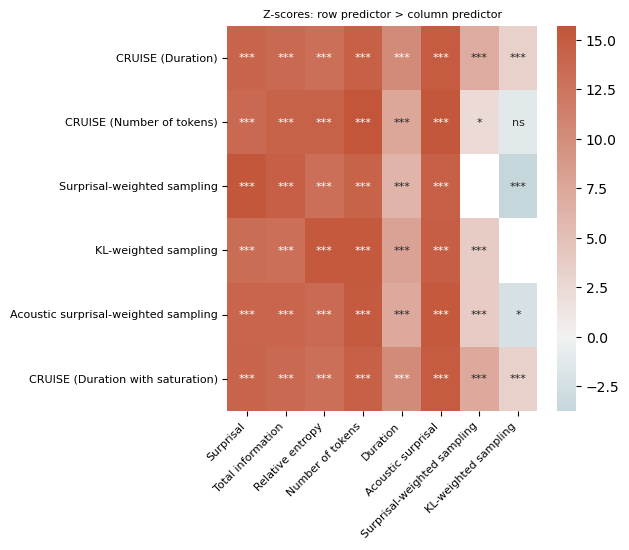

In [21]:
significance_matrix_from_z = combined_pvalue.map(lambda p: get_significance(p) if not pd.isna(p) else "")
fig,ax = plt.subplots(figsize = (5,5))

sns.heatmap(combined_zscores, annot=significance_matrix_from_z, 
            annot_kws ={'fontsize':plot_fontsize},
            fmt="", 
            ax=ax,
           xticklabels = [plotting_label_dict[s] for s in combined_zscores.columns],
           yticklabels = [plotting_label_dict[s] for s in combined_zscores.index],
           cmap = sns.diverging_palette(220, 20, as_cmap=True),center= 0)

ax.set_yticklabels(ax.get_yticklabels(), ha='right',fontsize = plot_fontsize)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right',fontsize = plot_fontsize)
ax.set_title('Z-scores: row predictor > column predictor',fontsize = plot_fontsize)
#fig.savefig(os.path.join(figure_save_dir,'second_level_matrix_full_%s_%s.svg'%(recall_str,inst_str)),transparent = True)

In [ ]:
figure_save_dir

Text(0.5, 1.0, 'Z-scores: red = row predictor > column predictor')

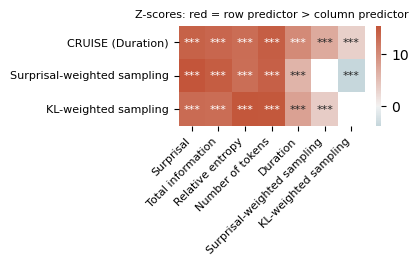

In [22]:
combined_zscores_mini = combined_zscores.loc[['weighted_event_info_by_duration','weighted_event_info_conditioned','weighted_event_info_kl'],
                                             ['H_event_conditioned', 'H_event', 'event_kl', 'event_len','event_duration','weighted_event_info_conditioned','weighted_event_info_kl']].copy()
significance_matrix_from_z = significance_matrix_from_z.loc[['weighted_event_info_by_duration','weighted_event_info_conditioned','weighted_event_info_kl'],
                                             ['H_event_conditioned', 'H_event', 'event_kl', 'event_len','event_duration','weighted_event_info_conditioned','weighted_event_info_kl']].copy()
fig,ax = plt.subplots(figsize = (3,1.3))

sns.heatmap(combined_zscores_mini, annot=significance_matrix_from_z, 
            annot_kws ={'fontsize':plot_fontsize},
            fmt="", 
            ax=ax,
           xticklabels = [plotting_label_dict[s] for s in combined_zscores_mini.columns],
           yticklabels = [plotting_label_dict[s] for s in combined_zscores_mini.index],
           cmap = sns.diverging_palette(220, 20, as_cmap=True),center= 0)

ax.set_yticklabels(ax.get_yticklabels(), ha='right',fontsize = plot_fontsize)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right',fontsize = plot_fontsize)
ax.set_title('Z-scores: red = row predictor > column predictor',fontsize = plot_fontsize)
#fig.savefig(os.path.join(figure_save_dir,'zscore_sig_matrix_%s_%s.svg'%(recall_str,inst_str)),transparent = True)

In [23]:
from scipy.stats import false_discovery_control
combined_pvalue_mini = combined_pvalue.loc[['weighted_event_info_by_duration','weighted_event_info_conditioned','weighted_event_info_kl'],
                                             ['H_event_conditioned', 'H_event', 'event_kl', 'event_len','event_duration','weighted_event_info_conditioned','weighted_event_info_kl']].copy()

arr = combined_pvalue_mini.to_numpy()

# True for valid p-values, False for NaNs
valid_mask = ~np.isnan(arr)

# Start with all NaNs
adjusted = np.full(arr.shape, np.nan, dtype=float)

# Apply FDR only to non-NaN p-values
adjusted[valid_mask] = false_discovery_control(
    arr[valid_mask],
    method="bh"
)

# Convert back to DataFrame with same shape/index/columns
combined_pvalue_mini_fdr = pd.DataFrame(
    adjusted,
    index=combined_pvalue_mini.index,
    columns=combined_pvalue_mini.columns
)

Text(0.5, 1.0, 'Z-scores: red = row predictor > column predictor')

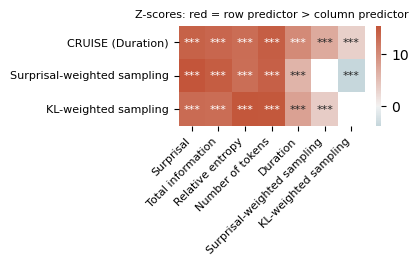

In [24]:
combined_zscores_mini = combined_zscores.loc[['weighted_event_info_by_duration','weighted_event_info_conditioned','weighted_event_info_kl'],
                                             ['H_event_conditioned', 'H_event', 'event_kl', 'event_len','event_duration','weighted_event_info_conditioned','weighted_event_info_kl']].copy()
significance_matrix_from_z_fdr = combined_pvalue_mini_fdr.map(lambda p: get_significance(p) if not pd.isna(p) else "")
fig,ax = plt.subplots(figsize = (3,1.3))

sns.heatmap(combined_zscores_mini, annot=significance_matrix_from_z_fdr, 
            annot_kws ={'fontsize':plot_fontsize},
            fmt="", 
            ax=ax,
           xticklabels = [plotting_label_dict[s] for s in combined_zscores_mini.columns],
           yticklabels = [plotting_label_dict[s] for s in combined_zscores_mini.index],
           cmap = sns.diverging_palette(220, 20, as_cmap=True),center= 0)

ax.set_yticklabels(ax.get_yticklabels(), ha='right',fontsize = plot_fontsize)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right',fontsize = plot_fontsize)
ax.set_title('Z-scores: red = row predictor > column predictor',fontsize = plot_fontsize)
#fig.savefig(os.path.join(figure_save_dir,'zscore_sig_matrix_%s_%s_fdr.svg'%(recall_str,inst_str)),transparent = True)

In [31]:
combined_pvalue_mini_fdr

,H_event_conditioned,H_event,event_kl,event_len,event_duration,weighted_event_info_conditioned,weighted_event_info_kl
weighted_event_info_by_duration,3.612252e-45,3.739625e-42,5.456229e-39,2.256419e-47,2.088914e-24,1.835481e-12,0.000975
weighted_event_info_conditioned,5.498126e-53,2.966468e-48,1.537626e-38,1.427936e-45,7.893748e-10,NaN,0.000189
weighted_event_info_kl,6.996221e-40,7.310992e-39,8.950305e-52,2.692916e-51,3.356323e-15,1.891545e-04,NaN


In [32]:
combined_pvalue_mini

,H_event_conditioned,H_event,event_kl,event_len,event_duration,weighted_event_info_conditioned,weighted_event_info_kl
weighted_event_info_by_duration,1.330830e-45,1.574579e-42,2.871699e-39,5.937944e-48,1.429257e-24,1.449064e-12,0.000975
weighted_event_info_conditioned,2.893751e-54,6.245196e-49,9.711324e-39,4.509271e-46,6.647367e-10,NaN,0.000179
weighted_event_info_kl,3.313999e-40,4.232679e-39,9.421374e-53,4.251972e-52,2.473080e-15,1.791990e-04,NaN


In [ ]:
figure_save_dir

## speech rate experiment 

In [25]:
save_dir = '../../generated'
sr_save_dir = "../../exp2/generated"
model_name = 'Llama3-8b-instruct' #'Llama3-8b'
model_save_dir_name = model_to_path_dict[model_name]['save_dir_name']
model_initial_char = model_to_path_dict[model_name]['initial_char']
figure_save_dir = os.path.join(save_dir,model_save_dir_name,'uniform_encoding','figures_even_split','adjusted')
if punctuated:
    static_preds = np.unique(controls+uniform_preds_punctuated+controls_punctuated)
else:
    static_preds = np.unique(controls+uniform_preds)

uniform_encoding_df_basename_timing = 'uniform_encoding_df_even_split_adjusted'
uniform_encoding_df_sr_original_name_timing = uniform_encoding_df_basename_timing+'_sr_original.csv'
uniform_encoding_df_sr_shrink_name_timing = uniform_encoding_df_basename_timing+'_sr_shrink.csv'

def get_sr_exp_corr_df(adjusted,sr_exp,shrink,punctuated):
    if adjusted:
        mutual_info_save_dir_name = 'story_split_timing_adjusted'
        figure_save_dir = os.path.join(save_dir,model_save_dir_name,'uniform_encoding','figures_even_split','adjusted')
        exclusion_dir = os.path.join('../../exp2/behavior_data/exclusion')


    if not os.path.exists(figure_save_dir):
        os.makedirs(figure_save_dir)


    stories = ['pieman','alternateithicatom','odetostepfather','souls','legacy','wheretheressmoke','adventuresinsayingyes','inamoment']
    story_to_idx_mapping = {s:stories.index(s)+1 for s in stories}

    uniform_preds_colors = {p:sns.color_palette("light:#005F5F_r", len(uniform_preds)+1)[i] for i,p in enumerate(uniform_preds)}
    controls_colors= {p:sns.color_palette("light:#FFBF00", len(controls)+1)[i+1] for i,p in enumerate(controls)}
    all_colors = {**uniform_preds_colors, **controls_colors}

    instruct = False
    recall_first = True



    all_stories_corr_df_sr = []
    for story in stories:
        if sr_exp:
            participant_info_df = pd.read_csv(os.path.join(exclusion_dir,'participant_info','%s_participant_info.csv'%story))
            if shrink:
                exclusion_df = pd.read_csv(os.path.join(exclusion_dir,'shrink','%s_exclusion.csv'%story))
                participants = participant_info_df.loc[participant_info_df['condition']=='shrink']['gorilla_id']
                story_uniform_encoding_df = all_uniform_encoding_dfs['shrink_sr'].loc[all_uniform_encoding_dfs['shrink_sr']['story']==story].copy()
                story_uniform_encoding_df = story_uniform_encoding_df.reset_index()
            else:
                exclusion_df = pd.read_csv(os.path.join(exclusion_dir,'original','%s_exclusion.csv'%story))
                participants = participant_info_df.loc[participant_info_df['condition']=='original']['gorilla_id']
                story_uniform_encoding_df = all_uniform_encoding_dfs['original_sr'].loc[all_uniform_encoding_dfs['original_sr']['story']==story].copy()
                story_uniform_encoding_df = story_uniform_encoding_df.reset_index()
        else:
            story_uniform_encoding_df = all_uniform_encoding_dfs['original_exp'].loc[all_uniform_encoding_dfs['original_exp']['story']==story].copy()
            story_uniform_encoding_df = story_uniform_encoding_df.reset_index()
        excluded_subjects = exclusion_df['excluded'].loc[exclusion_df['recall']==1].values 
        story_uniform_encoding_df = story_uniform_encoding_df.rename(columns={'H(event|prev events)': "H_event_conditioned", "H(event)": "H_event"})
        if not adjusted:
            story_uniform_encoding_df = None 

        pairwise_event_save_dir = os.path.join(sr_save_dir,model_save_dir_name,'pairwise_event',story,mutual_info_save_dir_name)

        recall_explained_event_info_df_raw = pd.read_csv(os.path.join(pairwise_event_save_dir,'recall_explained_event_ce_df.csv'))
        if sr_exp: # for sr exp, need to select the participants in that condition, then exclude
            recall_explained_event_info_df_raw = recall_explained_event_info_df_raw[recall_explained_event_info_df_raw['subject'].isin(participants)]
        recall_explained_event_info_df_raw = recall_explained_event_info_df_raw[~recall_explained_event_info_df_raw['subject'].isin(excluded_subjects)]

        event_explained_recall_info_df_raw = pd.read_csv(os.path.join(pairwise_event_save_dir,'event_explained_recall_ce_df.csv'))
        if sr_exp:
            event_explained_recall_info_df_raw = event_explained_recall_info_df_raw[event_explained_recall_info_df_raw['subject'].isin(participants)]
        event_explained_recall_info_df_raw = event_explained_recall_info_df_raw[~event_explained_recall_info_df_raw['subject'].isin(excluded_subjects)]

        recall_explained_event_info_df_instruct = pd.read_csv(os.path.join(pairwise_event_save_dir,'instruct','recall_explained_event_ce_df.csv'))
        if sr_exp:
            recall_explained_event_info_df_instruct = recall_explained_event_info_df_instruct[recall_explained_event_info_df_instruct['subject'].isin(participants)]
        recall_explained_event_info_df_instruct = recall_explained_event_info_df_instruct[~recall_explained_event_info_df_instruct['subject'].isin(excluded_subjects)]

        event_explained_recall_info_df_instruct = pd.read_csv(os.path.join(pairwise_event_save_dir,'instruct','event_explained_recall_ce_df.csv'))
        if sr_exp:
            event_explained_recall_info_df_instruct = event_explained_recall_info_df_instruct[event_explained_recall_info_df_instruct['subject'].isin(participants)]
        event_explained_recall_info_df_instruct = event_explained_recall_info_df_instruct[~event_explained_recall_info_df_instruct['subject'].isin(excluded_subjects)]


    
        subjects = []

        static_preds_corr = {pred:[] for pred in static_preds}
        if instruct:
            if recall_first:
                target_df = recall_explained_event_info_df_instruct
            else:
                target_df = event_explained_recall_info_df_instruct
        else:
            if recall_first:
                target_df = recall_explained_event_info_df_raw
            else:
                target_df = event_explained_recall_info_df_raw

        for subject,subject_df in target_df.groupby('subject'):
            ER_intersect = subject_df['ER_intersect'].values
            subjects.append(subject)
            for pred in static_preds:
                pred_story_val = story_uniform_encoding_df[pred]
                assert len(ER_intersect) == len(pred_story_val)
                static_preds_corr[pred].append(np.corrcoef(ER_intersect,pred_story_val)[0,1])


        recall_first_corr_df = pd.DataFrame({'subject':subjects,
                                            'story':story})
        for pred in static_preds:
            recall_first_corr_df[pred] = static_preds_corr[pred]
        all_stories_corr_df_sr.append(recall_first_corr_df)
    all_stories_corr_df_sr = pd.concat(all_stories_corr_df_sr, ignore_index =True)
    return all_stories_corr_df_sr

### no shrink version 

In [34]:
all_stories_corr_df_sr = get_sr_exp_corr_df(adjusted = True,sr_exp = True,shrink=False,punctuated =False)

In [35]:
targets = controls+['weighted_event_info_conditioned','weighted_event_info_kl']+['weighted_event_info_by_duration','weighted_event_info_exponential_saturation']

all_story_z_sr = get_all_story_z(all_stories_corr_df_sr,uniform_preds,targets)

In [36]:
combined_zscores,combined_pvalue = combine_zscores_from_stories(all_story_z_sr,uniform_preds,targets)
# drop CRUISE (Number of tokens) from the matrices
combined_zscores = combined_zscores.drop(index='weighted_event_info')
combined_pvalue = combined_pvalue.drop(index='weighted_event_info')

Text(0.5, 1.0, 'Z-scores: row predictor > column predictor')

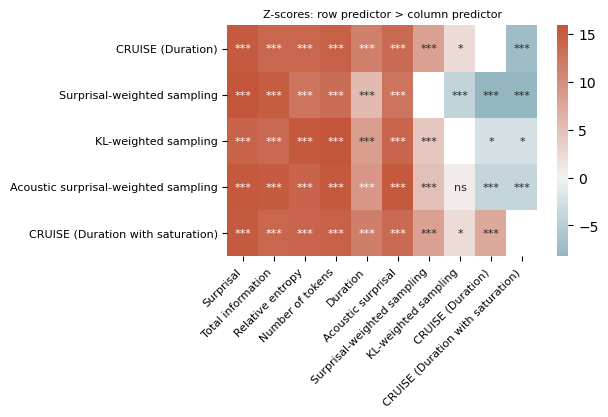

In [37]:
significance_matrix_from_z = combined_pvalue.map(lambda p: get_significance(p) if not pd.isna(p) else "")
fig,ax = plt.subplots(figsize = (5,3))

sns.heatmap(combined_zscores, annot=significance_matrix_from_z, 
            annot_kws ={'fontsize':plot_fontsize},
            fmt="", 
            ax=ax,
           xticklabels = [plotting_label_dict[s] for s in combined_zscores.columns],
           yticklabels = [plotting_label_dict[s] for s in combined_zscores.index],
           cmap = sns.diverging_palette(220, 20, as_cmap=True),center= 0)

ax.set_yticklabels(ax.get_yticklabels(), ha='right',fontsize = plot_fontsize)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right',fontsize = plot_fontsize)
ax.set_title('Z-scores: row predictor > column predictor',fontsize = plot_fontsize)
#fig.savefig(os.path.join(figure_save_dir,'second_level_matrix_full_%s_%s.svg'%(recall_str,inst_str)),transparent = True)

In [38]:
from scipy.stats import false_discovery_control
def fdr_correct_dedup(pvalue_df):
    # FDR (BH) across the matrix, counting each pair of predictors once:
    # (A,B) and (B,A) are the same comparison, so only the first occurrence enters the correction
    # and the duplicate entry gets the adjusted p-value of its counterpart
    arr = pvalue_df.to_numpy()
    adjusted = np.full(arr.shape, np.nan, dtype=float)
    first_occurrence = {}
    duplicates = []
    for i,row_pred in enumerate(pvalue_df.index):
        for j,col_pred in enumerate(pvalue_df.columns):
            if np.isnan(arr[i,j]):
                continue
            pair = frozenset((row_pred,col_pred))
            if pair in first_occurrence:
                duplicates.append(((i,j),first_occurrence[pair]))
            else:
                first_occurrence[pair] = (i,j)
    unique_idx = tuple(np.array(list(first_occurrence.values())).T)
    adjusted[unique_idx] = false_discovery_control(arr[unique_idx], method="bh")
    for (i,j),(i0,j0) in duplicates:
        adjusted[i,j] = adjusted[i0,j0]
    print('%d comparisons corrected, %d duplicate entries skipped'%(len(first_occurrence),len(duplicates)))
    return pd.DataFrame(adjusted, index=pvalue_df.index, columns=pvalue_df.columns)

In [39]:
combined_pvalue_fdr = fdr_correct_dedup(combined_pvalue)

40 comparisons corrected, 6 duplicate entries skipped


Text(0.5, 1.0, 'Z-scores: row predictor > column predictor (FDR corrected)')

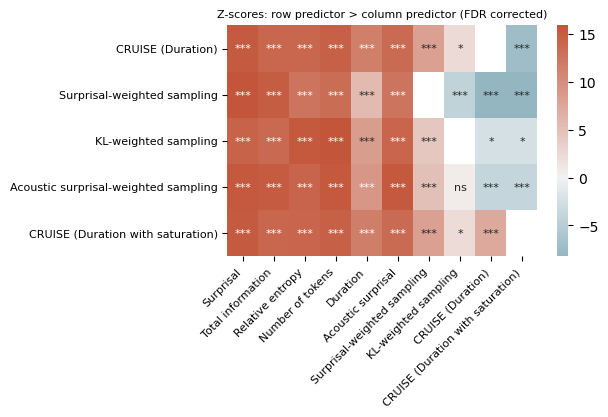

In [40]:
significance_matrix_from_z_fdr = combined_pvalue_fdr.map(lambda p: get_significance(p) if not pd.isna(p) else "")
fig,ax = plt.subplots(figsize = (5,3))

sns.heatmap(combined_zscores, annot=significance_matrix_from_z_fdr, 
            annot_kws ={'fontsize':plot_fontsize},
            fmt="", 
            ax=ax,
           xticklabels = [plotting_label_dict[s] for s in combined_zscores.columns],
           yticklabels = [plotting_label_dict[s] for s in combined_zscores.index],
           cmap = sns.diverging_palette(220, 20, as_cmap=True),center= 0)

ax.set_yticklabels(ax.get_yticklabels(), ha='right',fontsize = plot_fontsize)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right',fontsize = plot_fontsize)
ax.set_title('Z-scores: row predictor > column predictor (FDR corrected)',fontsize = plot_fontsize)
#fig.savefig(os.path.join(figure_save_dir,'second_level_matrix_full_sr_original_%s_%s_fdr.svg'%(recall_str,inst_str)),transparent = True)

### shrink 

In [41]:
all_stories_corr_df_sr = get_sr_exp_corr_df(adjusted = True,sr_exp = True,shrink = True,punctuated =False)

In [42]:
targets = controls+['weighted_event_info_conditioned','weighted_event_info_kl']+['weighted_event_info_by_duration','weighted_event_info_exponential_saturation']

all_story_z_sr = get_all_story_z(all_stories_corr_df_sr,uniform_preds,targets)

In [43]:
combined_zscores,combined_pvalue = combine_zscores_from_stories(all_story_z_sr,uniform_preds,targets)
# drop CRUISE (Number of tokens) from the matrices
combined_zscores = combined_zscores.drop(index='weighted_event_info')
combined_pvalue = combined_pvalue.drop(index='weighted_event_info')

Text(0.5, 1.0, 'Z-scores: row predictor > column predictor')

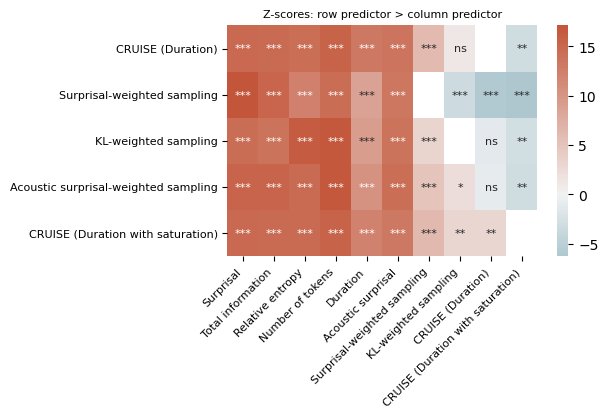

In [44]:
significance_matrix_from_z = combined_pvalue.map(lambda p: get_significance(p) if not pd.isna(p) else "")
fig,ax = plt.subplots(figsize = (5,3))

sns.heatmap(combined_zscores, annot=significance_matrix_from_z, 
            annot_kws ={'fontsize':plot_fontsize},
            fmt="", 
            ax=ax,
           xticklabels = [plotting_label_dict[s] for s in combined_zscores.columns],
           yticklabels = [plotting_label_dict[s] for s in combined_zscores.index],
           cmap = sns.diverging_palette(220, 20, as_cmap=True),center= 0)

ax.set_yticklabels(ax.get_yticklabels(), ha='right',fontsize = plot_fontsize)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right',fontsize = plot_fontsize)
ax.set_title('Z-scores: row predictor > column predictor',fontsize = plot_fontsize)
#fig.savefig(os.path.join(figure_save_dir,'second_level_matrix_full_%s_%s.svg'%(recall_str,inst_str)),transparent = True)

In [45]:
combined_pvalue_fdr = fdr_correct_dedup(combined_pvalue)

40 comparisons corrected, 6 duplicate entries skipped


Text(0.5, 1.0, 'Z-scores: row predictor > column predictor (FDR corrected)')

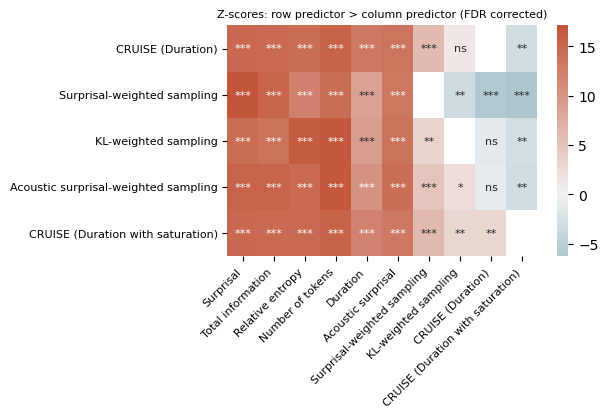

In [46]:
significance_matrix_from_z_fdr = combined_pvalue_fdr.map(lambda p: get_significance(p) if not pd.isna(p) else "")
fig,ax = plt.subplots(figsize = (5,3))

sns.heatmap(combined_zscores, annot=significance_matrix_from_z_fdr, 
            annot_kws ={'fontsize':plot_fontsize},
            fmt="", 
            ax=ax,
           xticklabels = [plotting_label_dict[s] for s in combined_zscores.columns],
           yticklabels = [plotting_label_dict[s] for s in combined_zscores.index],
           cmap = sns.diverging_palette(220, 20, as_cmap=True),center= 0)

ax.set_yticklabels(ax.get_yticklabels(), ha='right',fontsize = plot_fontsize)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right',fontsize = plot_fontsize)
ax.set_title('Z-scores: row predictor > column predictor (FDR corrected)',fontsize = plot_fontsize)
#fig.savefig(os.path.join(figure_save_dir,'second_level_matrix_full_sr_shrink_%s_%s_fdr.svg'%(recall_str,inst_str)),transparent = True)